<div style="width:100%; background-color:#181818; color:#f1f1f1; padding:30px 0; text-align:center; border-radius:10px;">
  <img src="https://media3.giphy.com/media/v1.Y2lkPTc5MGI3NjExeGZqamQ3dWQ2YWM4aW50OHZjdzRpN29sdWVhbnByYndpYzIyZW5jayZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9Zw/xT3i1ei3Ui7rpgrsyc/giphy.gif" alt="Reinforced concrete design animation" width="400" style="max-width:100%; border-radius:10px;">
  <h3 style="color:#ffffff; margin:0 0 8px 0;"><b>Column, Interaction Diagram</b></h3>
  <p style="margin:4px 0;"><b>Authors:</b> Msc. Ing. Carlos Andr&eacute;s Celi S&aacute;nchez &middot; Nicol&aacute;s Mora Bowen &middot; Juan Sebasti&aacute;n Baquero</p>
  <p style="margin:4px 0;"><b>Course:</b> Reinforced Concrete Design II</p>
</div>

### Libraries

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Data

In [29]:
Pu = 100*1e3
Mu = 400*1e5 

h = 150
b = 90
fc = 280
fy = 4200
Es = 2000000
ecu = 0.003
beta1 = 0.85

rec = 4
dvar_e =  1
num_capas = 10
dvar_f = 2.8
n_ext = 10               # bars in top AND bottom layers, same count (>= 2)
n_int = 2               # bars in each intermediate layer (>= 2)

In [30]:
dd = []
dini = rec + dvar_e + dvar_f/2
dfinal = h - rec - dvar_e - dvar_f/2
rango = dfinal - dini
size_div = rango / (num_capas-1)

for i in np.arange(0,num_capas,1):
    dd.append(dini + i*size_div)

dd = np.array(dd)
print(dd)

[  6.4         21.64444444  36.88888889  52.13333333  67.37777778
  82.62222222  97.86666667 113.11111111 128.35555556 143.6       ]


### Reinforcement layout and ratio check

In [31]:
if n_ext < 2 or (num_capas > 2 and n_int < 2):
    raise ValueError('Minimum 2 bars per layer (top/bottom corners, one per side face in intermediate layers)')

numvar = np.array([n_ext] + [n_int]*(num_capas - 2) + [n_ext])
dvar = np.full(num_capas, dvar_f)

Ag = b*h
Ast_prov = np.sum(np.pi*dvar**2/4*numvar)
rho_prov = Ast_prov/Ag
rho_min, rho_max = 0.01, 0.08                         # ACI 10.6.1.1

# clear spacing (ACI 25.2.3)
s_min = max(1.5*dvar_f, 4.0)
s_hor = (b - 2*(rec + dvar_e) - numvar*dvar_f)/(numvar - 1)   # between bars of each layer
s_ver = (dd[1] - dd[0]) - dvar_f                              # between layers

print('='*120)
print(f'numvar = {numvar}  (total {numvar.sum()} bars, db = {dvar_f*10:.0f} mm)')
print(f'Ast = {Ast_prov:.2f} cm2, Ag = {Ag:.2f} cm2 -> rho = {rho_prov*100:.2f} %')
print(f'rho_min = {rho_min*100:.0f} % ->', 'OK' if rho_prov >= rho_min else 'DOES NOT COMPLY')
print(f'rho_max = {rho_max*100:.0f} % ->', 'OK' if rho_prov <= rho_max else 'DOES NOT COMPLY')
print(f's_min = {s_min:.2f} cm')
for i, s in enumerate(s_hor):
    print(f'  layer {i+1}: s_clear = {s:.2f} cm ->', 'OK' if s >= s_min else 'DOES NOT COMPLY')
print(f'  between layers: s_clear = {s_ver:.2f} cm ->', 'OK' if s_ver >= s_min else 'DOES NOT COMPLY')
print('='*120)

numvar = [10  2  2  2  2  2  2  2  2 10]  (total 36 bars, db = 28 mm)
Ast = 221.67 cm2, Ag = 13500.00 cm2 -> rho = 1.64 %
rho_min = 1 % -> OK
rho_max = 8 % -> OK
s_min = 4.20 cm
  layer 1: s_clear = 5.78 cm -> OK
  layer 2: s_clear = 74.40 cm -> OK
  layer 3: s_clear = 74.40 cm -> OK
  layer 4: s_clear = 74.40 cm -> OK
  layer 5: s_clear = 74.40 cm -> OK
  layer 6: s_clear = 74.40 cm -> OK
  layer 7: s_clear = 74.40 cm -> OK
  layer 8: s_clear = 74.40 cm -> OK
  layer 9: s_clear = 74.40 cm -> OK
  layer 10: s_clear = 5.78 cm -> OK
  between layers: s_clear = 12.44 cm -> OK


### Calculation

In [32]:
ety = fy / Es
bwit = 0.85*fc

asi = np.pi * dvar**(2) / 4 * numvar 
Ag = b*h
Ast = np.sum(asi)
ratio  = Ast / Ag

yr = h/2
brp = np.abs(yr - dd)

cond = 0.1*Ag*fc

#--- Po,M---#
Po = 0.85*(fc*(Ag - Ast)) + fy*Ast
Pno = 0.8*(Po)
Mno = 0
fiPo = 0.65*Po
fiMno = 0.65*Mno

#--- Balance Point---#
cb = ecu / (ecu + ety) * dd[-1]
a_cb = beta1*cb
es_cb = np.abs(ecu*(dd-cb)/cb)
es_cb = np.where(es_cb > ety, ety, es_cb)
fs_cb = Es*es_cb
Cs_cb = asi * (np.where(dd <= cb, fs_cb, -fs_cb) - np.where(dd <= a_cb, bwit, 0))
Cc_cb = 0.85*fc*a_cb*b
Pn_cb = Cc_cb + np.sum(Cs_cb)
Mn_cb = Cc_cb * (yr - a_cb / 2) + np.sum(Cs_cb * (yr - dd))


if ratio >= 0.01:

    PN = []
    MN = []

    FIPN = []
    FIMN = []

    for cc in np.arange(h*1.1,0,-0.1):
        c = cc
        a = beta1*c

        #--Stress and Strain Steel--#
        esi = []
        fsi = []
        for i in np.arange(0,len(dd),1):
            esi.append(np.abs(ecu*(dd[i]-c)/c))
            if esi[i] <= ety:
                fsi.append(Es*esi[i])
            else:
                fsi.append(fy)

        #--Internal Forces / Steel--#
        Csi = []
        for i in np.arange(0,len(dd),1):
            if dd[i] <= a:
                Csi.append(asi[i]*(fsi[i] - bwit))
            else:
                Csi.append(asi[i]*fsi[i] * -1)
        Cc = bwit*a*b

        Pn = Cc + np.sum(Csi)

        #--Moments--#
        Mn = Cc*(yr - a/2) + np.sum(Csi * (yr - dd))

        #----Reduction factor----#
        aux = 0.1*fc*Ag
        if c >= cb:
            if Pn >= Pno:
                fi = 0.65
                fiPn = fi * Pno
                fiMn = fi * Mno
            else:
                fi = 0.65
                fiPn = fi * Pn
                fiMn = fi * Mn
        else:
            if aux <= Pn <= Pn_cb: 
                fi = 0.9 - (0.9 - 0.65) * (Pn - aux) / (Pn_cb - aux)
                fiPn = fi * Pn
                fiMn = fi * Mn
            else:
                fi = 0.90
                fiPn = fi * Pn
                fiMn = fi * Mn
        

        PN.append(Pn / 1000)
        MN.append(Mn / 1e5)

        FIPN.append(fiPn / 1000)
        FIMN.append(fiMn / 1e5)

        # print('='*120)
        # print('.'*90)
        # print('Geometry')
        # print(f'b = {b:.2f} cm , h = {h:.2f} cm')
        # print(f'Plastic Centroid = {yr:.2f} cm')
        # print(f'Neutral Axis = {c:.2f} cm')
        # print(f'a = {a:.2f} cm')
        # print(f'ds = {dd} cm')
        # print('.'*90)
        # print('Areas Materials')
        # print(f'As_i = {asi} cm2')
        # print(f'Ag = {Ag:.2f} cm2')
        # print('.'*90)
        # print('Strain Materials')
        # print(f'ety = {ety:.6f}')
        # print(f'es_i = {esi}')
        # print('.'*90)
        # print('Stess Materials')
        # print(f'fs_i = {fsi} kg/cm2')
        # print(f'0.85fc = {bwit:.2f} kg/cm2')
        # print('.'*90)
        # print('Force Materials')
        # print(f'Cs_i = {Csi} kg')
        # print(f'Cc = {Cc} kg')

        # print('.'*90)
        # print('Internal Capacity')
        # print(f'Pn = {Pn / 1000:.2f} T')
        # print(f'Mn = {Mn / 1e5:.2f} T-m')
        # print('='*120)

    # print(PN)
    # print(MN)
else:
    mensaje = {'error'}

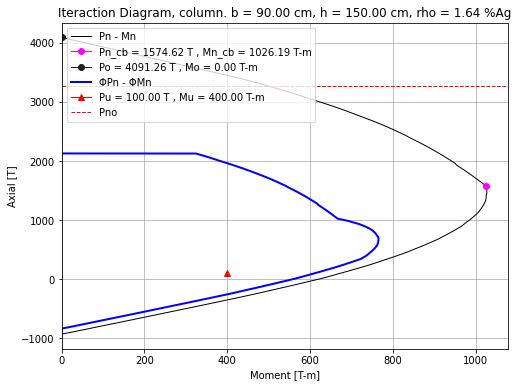

In [33]:
PNN = np.insert(PN,0,Po/1000)
MNN = np.insert(MN,0,Mno/1e5)

FIPNN = np.insert(FIPN,0,0.8*fiPo/1000)
FIMNN = np.insert(FIMN,0,0.8*fiMno/1e5)

fig, ax = plt.subplots(1,1, figsize = (8,6))
ax.plot(MNN,PNN, ls = '-', lw = 1, color = [0,0,0], label = 'Pn - Mn')

ax.plot(Mn_cb/1e5, Pn_cb/1000, ls = '-', lw = 1,marker = 'o', color = [1,0,1], 
        label = f'Pn_cb = {Pn_cb/1000:.2f} T , Mn_cb = {Mn_cb/1e5:.2f} T-m')

ax.plot(0, Po/1000, ls = '-', lw = 1,marker = 'o', color = [0.13,0.13,0.13], 
        label = f'Po = {Po/1000:.2f} T , Mo = {0:.2f} T-m')

ax.plot(FIMNN,FIPNN, ls = '-', lw = 2, color = [0,0,1], label = 'ΦPn - ΦMn')

ax.plot(Mu/1e5, Pu/1e3, ls = '-', lw = 1,marker = '^', color = [1,0,0], 
        label = f'Pu = {Pu/1000:.2f} T , Mu = {Mu/1e5:.2f} T-m')

ax.axhline(Pno/1000, ls = '--', lw = 1, color = [1,0,0], label = 'Pno')
ax.set_title(f'Iteraction Diagram, column. b = {b:.2f} cm, h = {h:.2f} cm, rho = {ratio*100:.2f} %Ag')
ax.set_xlabel('Moment [T-m]')
ax.set_ylabel('Axial [T]')
ax.set_xlim(0)
ax.grid()
ax.legend()

In [34]:
PN_df = pd.DataFrame(PNN)
PN_df

,0
0,4091.259621
1,3481.059899
2,3479.287141
3,3477.514440
4,3475.741798
...,...
1646,-921.913766
1647,-923.734466
1648,-925.555166
1649,-927.375866
